PROYECTO FINAL: Clasificación de Dígitos Mediante Redes Neuronales Convolucionales

Aguirre Medina Judit Alejandra - 217470949
Vázquez González Karla Ninoshka  - 222309196

In [21]:
#Importamos las librerias necesarias
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score , confusion_matrix
import seaborn as sns


INFORMACIÓN BÁSICA DEL DATASET MNIST:
Total de imágenes de entrenamiento: 60000
Total de imágenes de prueba: 10000
Dimensiones de cada imagen: (28, 28) (alto x ancho)
Total de clases: 10 (dígitos del 0 al 9)

DISTRIBUCIÓN DE CLASES (entrenamiento):
Dígito 0: 5923 muestras (9.9%)
Dígito 1: 6742 muestras (11.2%)
Dígito 2: 5958 muestras (9.9%)
Dígito 3: 6131 muestras (10.2%)
Dígito 4: 5842 muestras (9.7%)
Dígito 5: 5421 muestras (9.0%)
Dígito 6: 5918 muestras (9.9%)
Dígito 7: 6265 muestras (10.4%)
Dígito 8: 5851 muestras (9.8%)
Dígito 9: 5949 muestras (9.9%)

EJEMPLO DE IMAGEN:


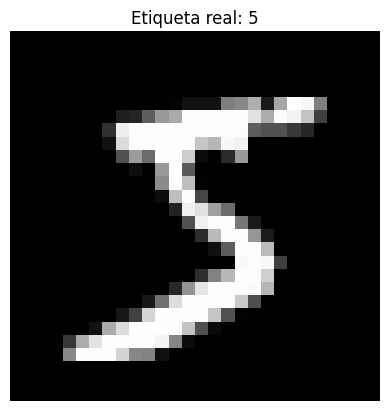

In [10]:
#Cargar dataset MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

#Información básica del dataset
print("\nINFORMACIÓN BÁSICA DEL DATASET MNIST:")
print(f"Total de imágenes de entrenamiento: {len(x_train)}")
print(f"Total de imágenes de prueba: {len(x_test)}")
print(f"Dimensiones de cada imagen: {x_train[0].shape} (alto x ancho)")
print(f"Total de clases: 10 (dígitos del 0 al 9)")

#Mostrar distribución de clases en entrenamiento
import numpy as np
unique, counts = np.unique(y_train, return_counts=True)
print("\nDISTRIBUCIÓN DE CLASES (entrenamiento):")
for digit, count in zip(unique, counts):
    print(f"Dígito {digit}: {count} muestras ({count/len(y_train)*100:.1f}%)")

#Mostrar ejemplo de imagen con su etiqueta
import matplotlib.pyplot as plt
print("\nEJEMPLO DE IMAGEN:")
plt.imshow(x_train[0], cmap='gray')
plt.title(f"Etiqueta real: {y_train[0]}")
plt.axis('off')
plt.show()

Iniciamos el entrenamiento de las imagenes

In [11]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

Nos aseguramos de la forma correcta del CNN/Canal de Color

In [12]:
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1)
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1)

print("Forma de x_train:", x_train.shape)
print("Forma de y_train:", y_train.shape)
print("Forma de x_test:", x_test.shape)
print("Forma de y_test:", y_test.shape)

Forma de x_train: (60000, 28, 28, 1)
Forma de y_train: (60000,)
Forma de x_test: (10000, 28, 28, 1)
Forma de y_test: (10000,)


Visualizamos

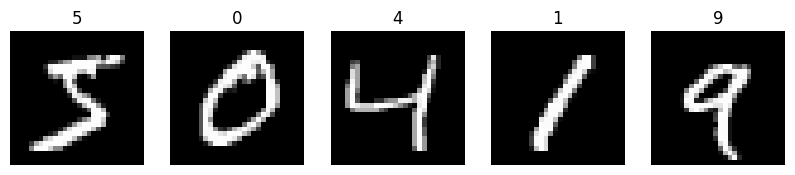

In [13]:
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.title(y_train[i])
    plt.axis('off')
plt.show()

Comenzamos a definir nuestra red neuronal para mas tarde comenzar con la compilación

In [14]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),   # 1ra capa convolucional
    tf.keras.layers.MaxPooling2D((2, 2)),                                             # 1ra capa de pooling
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),                            # 2da capa convolucional
    tf.keras.layers.MaxPooling2D((2, 2)),                                             # 2da capa de pooling
    tf.keras.layers.Flatten(),                                                        # Aplanamiento
    tf.keras.layers.Dense(128, activation='relu'),                                    # Capa densa oculta
    tf.keras.layers.Dense(10, activation='softmax')                                   # Capa de salida
])
model.summary()

#Se integraron dos capas convolucionales y dos capas de MaxPooling

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Comenzamos a compilar el modelo en conjunto con su presision y perdida

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 62s 32ms/step - accuracy: 0.9087 - loss: 0.3078 - val_accuracy: 0.9861 - val_loss: 0.0431
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 78s 30ms/step - accuracy: 0.9858 - loss: 0.0469 - val_accuracy: 0.9861 - val_loss: 0.0444
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 86s 32ms/step - accuracy: 0.9911 - loss: 0.0279 - val_accuracy: 0.9894 - val_loss: 0.0309
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 77s 29ms/step - accuracy: 0.9941 - loss: 0.0185 - val_accuracy: 0.9857 - val_loss: 0.0429
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 56s 30ms/step - accuracy: 0.9951 - loss: 0.0156 - val_accuracy: 0.9923 - val_loss: 0.0266
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 83s 30ms/step - accuracy: 0.9967 - loss: 0.0100 - val_accuracy: 0.9912 - val_loss: 0.0328
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 80s 29ms/step - accuracy: 0.9971 - loss: 0.0084 - val_accuracy: 0.9928 - val_loss: 0.0267
Epoch 8/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 84s 31ms/step - accuracy: 0.9975 -

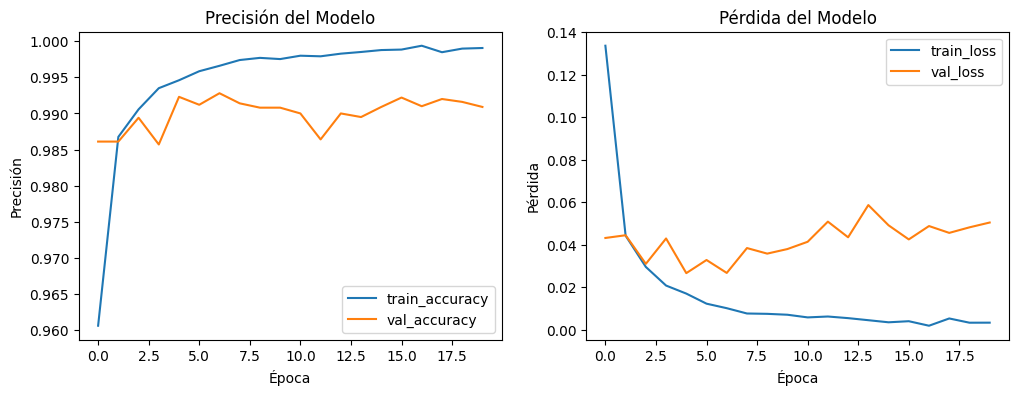

In [15]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


model.summary()

epochs = 20 #Aumentando el número de épocas antes eran 10
history = model.fit(x_train, y_train, epochs=epochs, validation_data=(x_test, y_test))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train_accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()
plt.title('Precisión del Modelo')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.title('Pérdida del Modelo')
plt.show()

Evaluación del Modelo

Precisión en el conjunto de prueba: 0.9909
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
F1-score en el conjunto de prueba: 0.9909


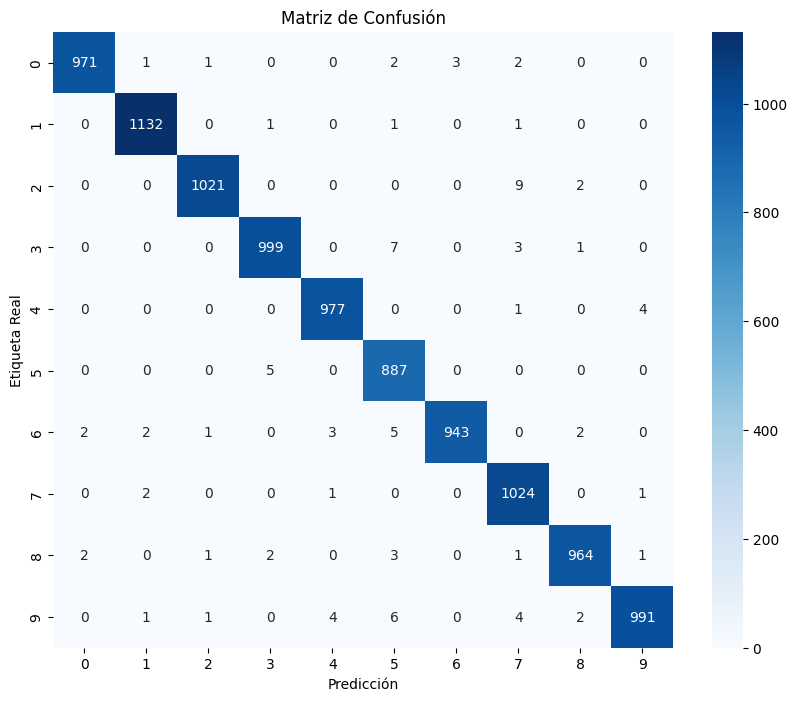

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


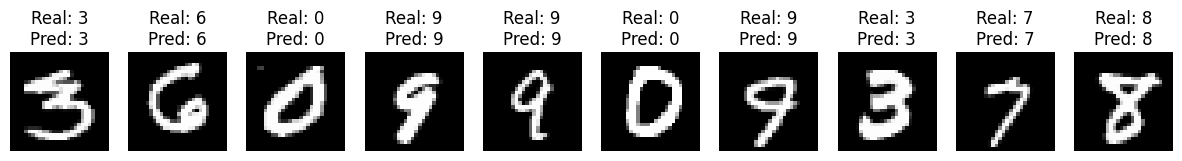

In [22]:
#I. Evaluar el modelo con el conjunto de prueba
loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f'Precisión en el conjunto de prueba: {accuracy:.4f}')

#II. Calcular el f1-score
y_pred_probs = model.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)
f1 = f1_score(y_test, y_pred, average='weighted')
print(f'F1-score en el conjunto de prueba: {f1:.4f}')

#III. Graficar la matriz de confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción')
plt.ylabel('Etiqueta Real')
plt.title('Matriz de Confusión')
plt.show()

#IV. Graficar algunas predicciones
num_samples = 10
indices = np.random.choice(len(x_test), num_samples, replace=False)
predicted_labels = np.argmax(model.predict(x_test[indices]), axis=1)
true_labels = y_test[indices]
images = x_test[indices].reshape(num_samples, 28, 28)

plt.figure(figsize=(15, 3))
for i in range(num_samples):
    plt.subplot(1, num_samples, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(f'Real: {true_labels[i]}\nPred: {predicted_labels[i]}')
    plt.axis('off')
plt.show()

Subir la imagen, la conversion y la dimension junto con la prediccion

Saving 1 cs.png to 1 cs (1).png
Usuario subió el archivo "1 cs (1).png" con longitud 35769 bytes
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


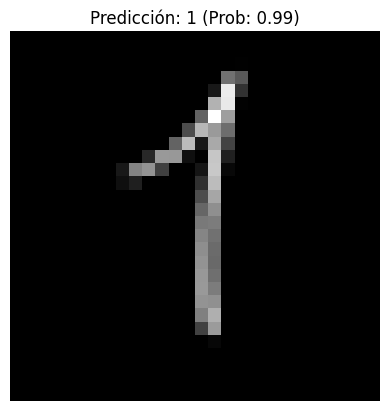

In [55]:
from google.colab import files
from PIL import Image

uploaded = files.upload()  #Subir imagen

imagen_path = None
for filename in uploaded.keys():
    print(f'Usuario subió el archivo "{filename}" con longitud {len(uploaded[filename])} bytes')
    imagen_path = filename
    break
if imagen_path:
    try:

        img = Image.open(imagen_path).convert('L')  #Convertir a escala de grises


        img_resized = img.resize((28, 28))


        img_inverted = Image.eval(img_resized, lambda p: 255 - p)
        img_array = np.array(img_inverted).astype('float32') / 255.0


        img_reshaped = img_array.reshape(1, 28, 28, 1)

        #Predicción
        predicciones = model.predict(img_reshaped)
        digito_predicho = np.argmax(predicciones)
        probabilidad = np.max(predicciones)


        plt.imshow(img_inverted, cmap='gray')
        plt.title(f'Predicción: {digito_predicho} (Prob: {probabilidad:.2f})')
        plt.axis('off')
        plt.show()

    except FileNotFoundError:
        print(f"Error: No se encontró la imagen en la ruta: {imagen_path}")
    except Exception as e:
        print(f"Ocurrió un error al procesar la imagen: {e}")
else:
    print("No se subió ninguna imagen para la clasificación.")